## Assignment 5 and 6: <font color='3C6E71'> Who Gets the State Grant?</font>

### Presentation: Week 8 practice session
### Total Points: 5 points
### Team: 3 students
### **Team Name:** `steelpipe`
### **Members:** Akzhol, Mansur

Fill this table or look for team form there: [link](https://docs.google.com/spreadsheets/d/1Um-SZ_GsSQDTiPsXOLVdytGYG5y507-5p7N15vlsRdg/edit?usp=sharing)



github link: [link](https://github.com/qrtxx/assignment56)

---
## The story
Every year the state publishes the list of school graduates who received an education grant. The lists are huge PDF files: names, exam scores, university codes and majors, with a different list for each major. In this assignment you must turn **raw PDF pages into a clean, integrated dataset**, analyse it, and present what you found.

> **Pipeline:** PDF pages → raw table → cleaned data → integrated data → analysis → visualizations → presentation

Data Grant lists (PDF):
- [2026 grant list](https://www.gov.kz/uploads/2026/8/7/9f5001ceea340a035bacebc8883be8e1_original.50845887.pdf)

- [2025 grant list](https://www.gov.kz/uploads/2025/8/7/af433aa904fa3ae1ae0806bd73d3501d_original.34169829.pdf)

- [2024 grant list](https://www.gov.kz/uploads/2024/8/3/4d83c2959534c05a1b3b1a29f4828dd9_original.25519389.pdf)

- [2023 grant list](https://farabi.university/storage/files/204293661064cde74be1b02162932678_%D0%93%D1%80%D0%B0%D0%BD%D1%82%20%D0%B8%D0%B5%D0%B3%D0%B5%D1%80%D0%BB%D0%B5%D1%80%D1%96%D0%BD%D1%96%D2%A3%20%D1%82%D1%96%D0%B7%D1%96%D0%BC%D1%96%202023.pdf)

- [2022 grant list](https://drive.google.com/file/d/1AIfLpFp9XUYJSXaVdfd13Eu3EruAFyOt/view)

Exam score distributions per subject combination and year (images from the testing center):

[images link](https://drive.google.com/drive/folders/1ykr7NXY-HcExgomwknudsH_tTnsDCKcg?usp=sharing)


Task:
- Choose one subject combination. For example Math-Informatics
- Extract the data from the PDFs (and type in the exam distributions from the images if you use them).
- Add new column with University name
- Choose 4 interesting questions about the data. Each question must be answerable with the data (counts, shares, min, median, percentiles, IQR, trends).
    Examples:
    
    Groups:
    - Which program group gets the most grants each year, and does that change?
    - Which group has the highest typical (median) score, and which has the lowest?
    - Which group’s minimum score changed the most between the first and last year?
    - Which group is the most stable year to year, and which is the hardest to predict?
    - Which groups would have been “safe”, “borderline” or “risky” for score S?
    - In which group are the scores most spread out, and what does that mean for a student with S?

    Universities
    - Which universities have the highest minimum scores in each group, and are they the same every year?
    - Which universities would have accepted S in all years (only those with enough recipients)?
    - How concentrated are the grants? What share goes to the top 3 universities in a group?
    - Which universities gained or lost the most grants over the years?

    Change over time
    - Is the lowest grant score going up or down in each group?
    - Did the number of grants change, and did the minimum score move in the same direction?



- Answer each question with one plot (4 plots in total).
- Present in the Week 8 practice session (8-10 minutes, every member presents).


**Rules**

- Drop the name column right after extraction and never show names.
- Use descriptive statistics only (counts, shares, min, median, percentiles, IQR, z-score). Do not claim “X% chance”.
- Show one data check, for example your extracted row count against the last number of the list.
- Each plot’s title is its answer. For each plot, say one sentence with the number and one sentence on the limit of the answer.



## 0. Dataset
Cleaned datasets: **`grants_2022_2026.csv` and `math_physics_general.csv`**

Source PDFs: the five grant lists linked above, saved as `pdfs/2022.pdf` … `pdfs/2026.pdf`.
Subject combination: **Math–Physics**. Years: **2022–2026**.

In [9]:
import re
import pymupdf
import pandas as pd
import matplotlib.pyplot as plt

YEARS = [2022, 2023, 2024, 2025, 2026]

#MathPhys
MATH_PHYSICS = ["B009", "B010", "B054", "B055", "B056", "B059", "B061", "B062", "B063", "B064",
                "B065", "B066", "B067", "B069", "B070", "B071", "B074", "B076", "B081", "B082",
                "B094", "B097", "B167", "B183"]
CATEGORY = {"B009": "teacher", "B010": "teacher",
            "B054": "science", "B055": "science", "B056": "science"}

## 1. Extraction
Each PDF contains many lists. We read only the first one: the **general competition** for
full-time study. In the text, every grant holder is a few lines:

```
1             <- row number
123456789     <- 9-digit test ID   (not kept)
SURNAME NAME  <- name, 1–2 lines   (not kept)
137           <- total score
013           <- university code
```

Quota is a heading above the rows (`ОБЩИЙ КОНКУРС` / `СЕЛЬСКАЯ КВОТА`), except in 2024, where it
is a cell after the university code (`ауылдық` = rural, `ТЖ` = emergency regions after the floods).
In 2022–2024 the teacher groups also have a separate English-medium department at the end.

In [10]:
GROUP_HEADER = re.compile(r"^B\d{3}.* - ")
TEST_ID = re.compile(r"^(?:(\d{1,5})\s+)?\d{9}(?:\s|$)")
UNIVERSITY = re.compile(r"^(\d{3}) - (.+)$")
NEXT_LIST = re.compile(r"СПИСОК ОБЛАДАТЕЛЕЙ|Список обладателей|тізімі|ТІЗІМІ|СОКРАЩЕННАЯ|ҚЫСҚАРТЫЛҒАН")
QUOTA_HEADINGS = {"ОБЩИЙ КОНКУРС": "general", "ЖАЛПЫ КОНКУРС": "general",
                  "СЕЛЬСКАЯ КВОТА": "rural", "АУЫЛ КВОТАСЫ": "rural"}
QUOTA_CELLS_2024 = {"ауылдық": "rural", "ТЖ": "emergency"}
ENGLISH_HEADINGS = ["АНГЛИЙСКОЕ ОТДЕЛЕНИЕ", "АҒЫЛШЫН БӨЛІМІ"]


def read_lines(year):
    lines = []
    for page in pymupdf.open(f"pdfs/{year}.pdf"):
        page_lines = [line.strip() for line in page.get_text().split("\n") if line.strip()]
        if year != 2022 and page_lines and page_lines[0] == str(page.number + 1):
            page_lines = page_lines[1:]
        lines += page_lines
    return lines


def find_number(lines, i, step):
    while not lines[i].isdigit():
        i += step
    return i


def parse_first_list(lines, year):
    rows = []
    group, section, quota, track = None, 0, "general", "main"
    for i, line in enumerate(lines):
        if GROUP_HEADER.match(line):
            group, section, quota = line[:4], section + 1, "general"
        elif group is None:
            continue
        elif NEXT_LIST.search(line):
            break
        elif line in QUOTA_HEADINGS:
            quota = QUOTA_HEADINGS[line]
        elif line in ENGLISH_HEADINGS:
            track = "english"
        elif TEST_ID.match(line):
            row_no = TEST_ID.match(line).group(1) or lines[find_number(lines, i - 1, -1)]
            score_i = find_number(lines, i + 1, 1)
            uni_i = find_number(lines, score_i + 1, 1)
            rows.append({"year": year, "section": section, "group_code": group, "track": track,
                         "quota": QUOTA_CELLS_2024.get(lines[uni_i + 1], quota),
                         "row_no": int(row_no), "score": int(lines[score_i]), "uni_code": lines[uni_i]})
    return rows


rows, uni_names = [], {}
for year in range(2022, 2027):
    lines = read_lines(year)
    rows += parse_first_list(lines, year)
    for line in lines:
        match = UNIVERSITY.match(line)
        if match and match.group(1) not in uni_names:
            uni_names[match.group(1)] = match.group(2)

grants = pd.DataFrame(rows)
grants["uni_name"] = grants.uni_code.map(uni_names).fillna("code " + grants.uni_code)
grants.groupby("year").size()

year
2022    37563
2023    37762
2024    44216
2025    41733
2026    38712
dtype: int64

## 2. Data check
In every group list, the number of rows we extracted should equal the last row number printed in
the PDF.

In [11]:
check = grants.groupby(["year", "section"]).row_no.agg(["count", "max"])
# print(check)
print(f"{(check['count'] == check['max']).sum()} of {len(check)} group lists: extracted rows = last row number")
print(f"Scores from {grants.score.min()} to {grants.score.max()} (maximum possible is 140)")

489 of 489 group lists: extracted rows = last row number
Scores from 50 to 140 (maximum possible is 140)


## 3. Cleaning
Keep Math–Physics groups, the general competition (not the rural or 2024 emergency quotas) and
the main track (not the small English-medium sections). Drop groups with fewer than 20 grants in
any year.

In [12]:
mp = grants[grants.group_code.isin(MATH_PHYSICS) & (grants.quota == "general") & (grants.track == "main")]
per_year = pd.crosstab(mp.group_code, mp.year)
kept = per_year.index[(per_year >= 20).all(axis=1)]
print("Dropped groups:", sorted(set(MATH_PHYSICS) - set(kept)))

mp = mp[mp.group_code.isin(kept)].copy()
mp["category"] = mp.group_code.map(CATEGORY).fillna("engineering")

grants.to_csv("grants_2022_2026.csv", index=False)
mp.to_csv("math_physics_general.csv", index=False) ## Мына жакта можно и сактамаяк коюга особо смысл жок но оставил
print(f"{len(mp):,} grant holders in {len(kept)} groups")

Dropped groups: ['B069', 'B081', 'B097']
58,331 grant holders in 21 groups


## 4. Analysis
### Q1. Is getting a grant getting harder?

        count       mean        std   min   25%   50%    75%    max
year                                                               
2022  12836.0  74.378623  18.404759  50.0  61.0  69.0   84.0  140.0
2023  13033.0  78.658712  19.917875  50.0  62.0  75.0   92.0  139.0
2024  11569.0  79.576022  20.751296  50.0  63.0  76.0   94.0  139.0
2025  11108.0  82.583093  20.972619  50.0  65.0  79.0   98.0  140.0
2026   9785.0  89.105979  19.612495  50.0  74.0  88.0  104.0  140.0


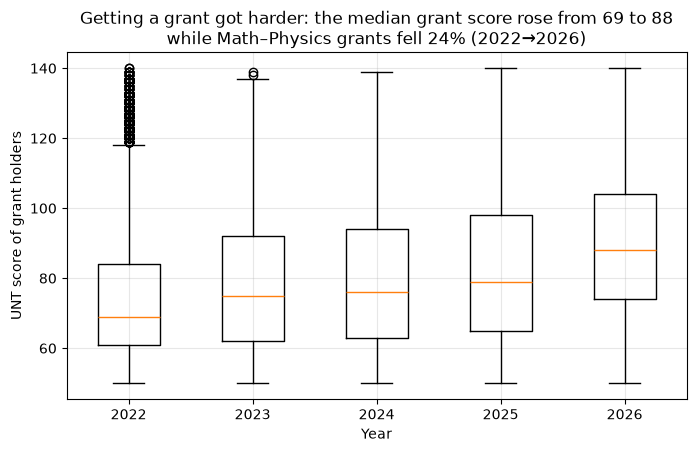

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2022,12836.0,74.0,18.0,50.0,61.0,69.0,84.0,140.0
2023,13033.0,79.0,20.0,50.0,62.0,75.0,92.0,139.0
2024,11569.0,80.0,21.0,50.0,63.0,76.0,94.0,139.0
2025,11108.0,83.0,21.0,50.0,65.0,79.0,98.0,140.0
2026,9785.0,89.0,20.0,50.0,74.0,88.0,104.0,140.0


In [13]:
summary = mp.groupby("year").score.describe()
print(summary)
drop = 1 - summary["count"][2026] / summary["count"][2022]

plt.figure(figsize=(8, 4.5))
plt.boxplot([mp[mp.year == year].score for year in YEARS])
plt.xticks([1, 2, 3, 4, 5], YEARS)
plt.title(f"Getting a grant got harder: the median grant score rose from {summary['50%'][2022]:.0f} "
          f"to {summary['50%'][2026]:.0f}\nwhile Math–Physics grants fell {drop:.0%} (2022→2026)")
plt.xlabel("Year")
plt.ylabel("UNT score of grant holders")
plt.grid(True, alpha=0.3)
plt.show()
summary.round(0)

**Number:** the median score of Math–Physics grant holders rose from 69 (2022) to 88 (2026), and the lower
quartile from 61 to 74, while the number of general-competition grants in these groups fell from
12,836 to 9,785 (−24%).

**Limit:** we only see students who *won* a grant, not everyone who took the test. A higher
median can come from more competition, an easier exam or fewer grants, and this data cannot
separate those. In 2024 part of the grants also went to the separate emergency-regions quota.

### Q2. What is the cheapest way in: teacher training or engineering?
For each group and year we take the minimum grant score, then the median of those minimums in
each category.

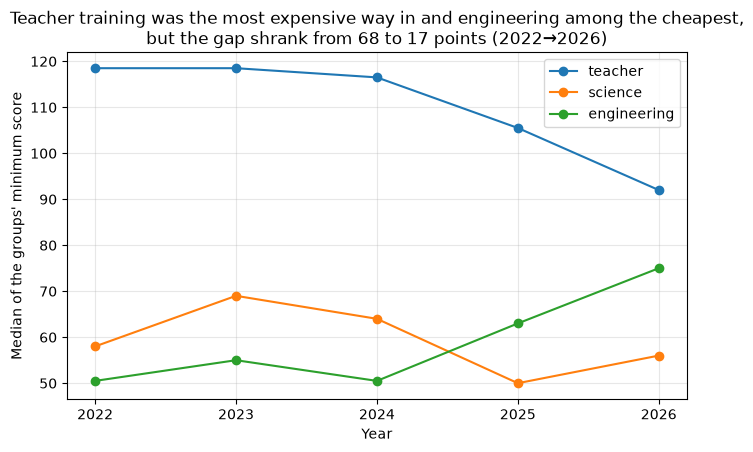

category,engineering,science,teacher
year,,,
2022,50.5,58.0,118.5
2023,55.0,69.0,118.5
2024,50.5,64.0,116.5
2025,63.0,50.0,105.5
2026,75.0,56.0,92.0


In [14]:
group_min = mp.groupby(["category", "group_code", "year"]).score.min()
category_min = group_min.groupby(["year", "category"]).median().unstack()
gap = category_min["teacher"] - category_min["engineering"]

plt.figure(figsize=(8, 4.5))
for category in ["teacher", "science", "engineering"]:
    plt.plot(category_min.index, category_min[category], "o-", label=category)
plt.title(f"Teacher training was the most expensive way in and engineering among the cheapest,\n"
          f"but the gap shrank from {gap[2022]:.0f} to {gap[2026]:.0f} points (2022→2026)")
plt.xlabel("Year")
plt.ylabel("Median of the groups' minimum score")
plt.xticks(YEARS)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
category_min

**Number:** the median minimum of the two teacher-training groups (B009 maths teachers, B010
physics teachers) fell from 118.5 (2022) to 92 (2026), while that of the 16 engineering groups rose
from 50.5 to 75. The gap shrank from 68 to 17 points. The 3 science groups stayed low (56 in 2026).

**Limit:** a minimum is set by a single student, so it moves a lot. A minimum of 50 (the lowest
score on any grant) only says the group took everyone above that score, not how hard it was to
get in. Teacher programmes may also have their own admission thresholds, which the PDFs don't show.

### Q3. Where do top scorers go?
Top scorers are the top 10% of Math–Physics grant holders **within each year**, so the
definition stays fair as scores rise.

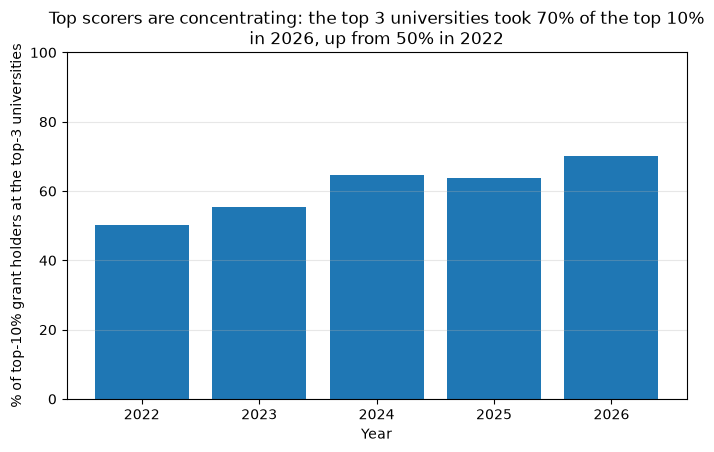

top_scorers  \
year university                                                              
2022 Казахский национальный университет имени аль-Фараби               286   
     Евразийский национальный университет имени Л.Н. Гумилева          212   
     Казахстанско-Британский технический университет                   188   
2023 Казахстанско-Британский технический университет                   297   
     Евразийский национальный университет имени Л.Н. Гумилева          261   
     Университет имени Сулеймана Демиреля                              220   
2024 Казахстанско-Британский технический университет                   288   
     Евразийский национальный университет имени Л.Н. Гумилева          259   
     Университет имени Сулеймана Демиреля                              230   
2025 Казахстанско-Британский технический университет                   308   
     Евразийский национальный университет имени Л.Н. Гумилева          301   
     Университет имени Сулеймана Демиреля                              150   
2026 Казахстанско-Британский технический университет                   343   
     Евразийский национальный университет имени Л.Н. Гумилева          275   
     Университет имени Сулеймана Демиреля                              115   

                                                               share  
year university                                                       
2022 Казахский национальный университет имени аль-Фараби        0.21  
     Евразийский национальный университет имени Л.Н. Гумилева   0.16  
     Казахстанско-Британский технический университет            0.14  
2023 Казахстанско-Британский технический университет            0.21  
     Евразийский национальный университет имени Л.Н. Гумилева   0.19  
     Университет имени Сулеймана Демиреля                       0.16  
2024 Казахстанско-Британский технический университет            0.24  
     Евразийский национальный университет имени Л.Н. Гумилева   0.22  
     Университет имени Сулеймана Демиреля                       0.19  
2025 Казахстанско-Британский технический университет            0.26  
     Евразийский национальный университет имени Л.Н. Гумилева   0.25  
     Университет имени Сулеймана Демиреля                       0.13  
2026 Казахстанско-Британский технический университет            0.33  
     Евразийский национальный университет имени Л.Н. Гумилева   0.26  
     Университет имени Сулеймана Демиреля                       0.11

In [15]:
results = []        # one row per year
top3_rows = []      # one row per year and university
for year in YEARS:
    this_year = mp[mp.year == year]
    top = this_year[this_year.score >= this_year.score.quantile(0.9)]
    top3 = top.uni_name.value_counts().head(3)
    results.append({"year": year, "top_scorers": len(top), "top3_share": top3.sum() / len(top)})
    for university, count in top3.items():
        top3_rows.append({"year": year, "university": university, "top_scorers": count,
                          "share": round(count / len(top), 2)})
q3 = pd.DataFrame(results).set_index("year")

plt.figure(figsize=(8, 4.5))
plt.bar(q3.index, q3.top3_share * 100)
plt.title(f"Top scorers are concentrating: the top 3 universities took {q3.top3_share[2026]:.0%} "
          f"of the top 10%\nin 2026, up from {q3.top3_share[2022]:.0%} in 2022")
plt.xlabel("Year")
plt.ylabel("% of top-10% grant holders at the top-3 universities")
plt.ylim(0, 100)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

pd.set_option("display.max_colwidth", None)     # show full university names
pd.DataFrame(top3_rows).set_index(["year", "university"])

**Number:** the top 10% of grant holders (101+ points in 2022, 116+ in 2026) increasingly went to
the same three universities: 50% in 2022 and 70% in 2026. Since 2023 those three have been
Kazakh-British Technical University, L.N. Gumilyov Eurasian National University and Suleyman
Demirel University.

**Limit:** the "top 3" can be different universities in different years (2022 differs from the
later years), and about 3% of grant holders study at universities whose code has no name in the
PDFs (shown as "code …").

### Q4. Do more grants mean easier entry?
Each dot is one group from one year to the next (21 groups × 4 pairs of years = 84 dots).

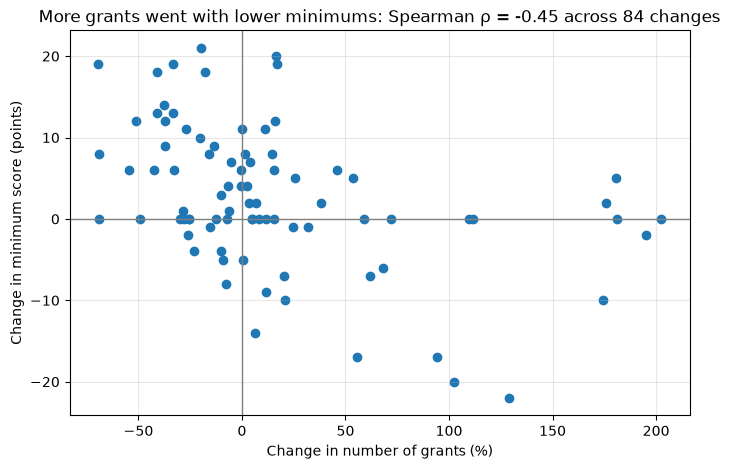

Spearman rho = -0.45; without the year pairs touching 2024: -0.32 (42 changes)


In [16]:
per_group = mp.groupby(["group_code", "year"]).score.agg(grants="count", minimum="min").reset_index()
next_year = per_group.copy()
next_year["year"] = next_year["year"] - 1          # put next year's values on this year's row
pairs = per_group.merge(next_year, on=["group_code", "year"], suffixes=("", "_next"))
pairs["grants_change"] = (pairs.grants_next - pairs.grants) / pairs.grants * 100
pairs["minimum_change"] = pairs.minimum_next - pairs.minimum

rho = pairs.grants_change.corr(pairs.minimum_change, method="spearman")
no_2024 = pairs[(pairs.year != 2023) & (pairs.year != 2024)]   # without pairs into or out of 2024
rho_no_2024 = no_2024.grants_change.corr(no_2024.minimum_change, method="spearman")

plt.figure(figsize=(8, 5))
plt.scatter(pairs.grants_change, pairs.minimum_change)
plt.axhline(0, color="gray", linewidth=1)
plt.axvline(0, color="gray", linewidth=1)
plt.title(f"More grants went with lower minimums: Spearman ρ = {rho:.2f} across {len(pairs)} changes")
plt.xlabel("Change in number of grants (%)")
plt.ylabel("Change in minimum score (points)")
plt.grid(True, alpha=0.3)
plt.show()
print(f"Spearman rho = {rho:.2f}; without the year pairs touching 2024: {rho_no_2024:.2f} ({len(no_2024)} changes)")

**Number:** across 84 group-year changes, groups that gained grants tended to have lower minimums
the next year (Spearman ρ = −0.45). Without the pairs into or out of 2024 it is −0.32 (42 changes),
so the 2024 emergency quota is not the whole story.

**Limit:** this is a correlation, not a cause. The number of applicants also changes, and we
don't see it. Where a group's minimum sat at 50 in both years, it can't fall any further, which
flattens the relationship.

---
# Submission Checklist


- `.ipynb` with Dataset link and code
- Report about the work and each student contribution
- Presentation



---
### **Grading (5 points)**

**Questions and plots**, 4.0 points. Each question is worth its level’s maximum × its quality, and the total is capped at 4.0. Quality means correct data and method (50%), a clear plot (25%), and an honest interpretation with limits (25%).

**Presentation**, 1.0 point. Clear story (0.4), every member presents and answers questions (0.4), honest limits (0.2).

| Level | Max points | What it looks like                                     | Examples                                                                                                                                                                          |
| ----- | ---------- | ------------------------------------------------------ | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1     | 0.75       | One year or one group, one simple summary              | Which group got the most grants in 2026? How many students scored at or above X?                                                                                                  |
| 2     | 1.0        | Several years or groups compared, some cleaning needed | Which group’s minimum score changed the most between the first and last year, and which group is the most stable? Which universities are on top for a group over the years?                       |
